In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
np.random.seed(42)
data = {
    'CustomerID': np.arange(1, 101),
    'Age': np.random.randint(18, 65, size=100),
    'Average_Spend': np.random.uniform(5, 50, size=100),
    'Visits_per_week': np.random.uniform(1, 4, size=100),
    'Promotion_Intrest': np.random.uniform(1, 11, size=100)
}
df = pd.DataFrame(data)


In [14]:
features = df[['Age', 'Average_Spend', 'Visits_per_week', 'Promotion_Intrest']]


scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)


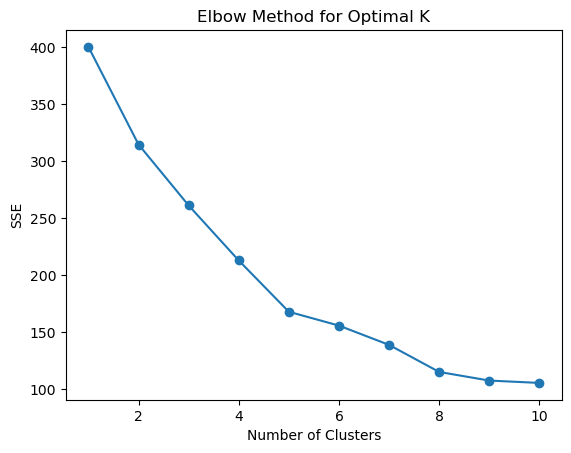

In [15]:

sse = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(features_scaled)
    sse.append(kmeans.inertia_)

plt.plot(k_range, sse, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('SSE')
plt.title('Elbow Method for Optimal K')
plt.show()



In [17]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(features_scaled)

In [18]:
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features.columns)
cluster_names = {}
for i, row in centroids.iterrows():
    if row['Visits_per_week'] > 2.5:   # high visits → Daily
        cluster_names[i] = "Daily"
    elif row['Average_Spend'] > 30:    # high spend → Promotion
        cluster_names[i] = "Promotion"
    else:
        cluster_names[i] = "Weekend"

In [19]:
df['Customer Group'] = df['Cluster'].map(cluster_names)

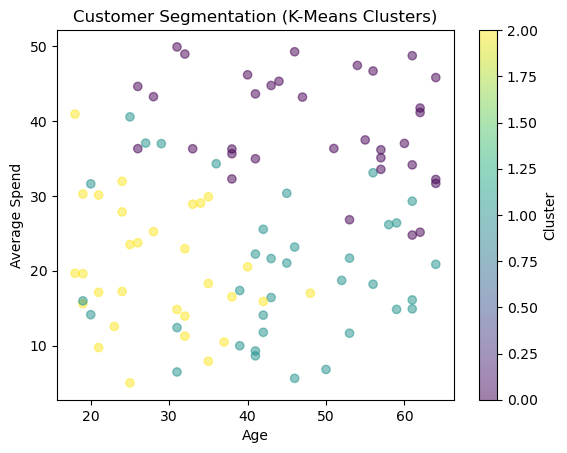

In [20]:

plt.scatter(df['Age'], df['Average_Spend'], c=df['Cluster'], cmap='viridis', alpha=0.5)
plt.xlabel("Age")
plt.ylabel("Average Spend")
plt.title("Customer Segmentation (K-Means Clusters)")
plt.colorbar(label="Cluster")
plt.show()

In [21]:
print("Silhouette Score:", silhouette_score(features_scaled, df['Cluster']))


Silhouette Score: 0.20256038910412338


In [22]:
def clustering(age, avg_spend, visit_per_week, promotion_intrest):
    new_customer = scaler.transform([[age, avg_spend, visit_per_week, promotion_intrest]])
    predicted_cluster = kmeans.predict(new_customer)[0]
    return cluster_names[predicted_cluster]

In [28]:
age = 35
avg_spend = 40
visit_per_week = 2
promotion_intrest = 7
print("New customer assigned to cluster:", clustering(age, avg_spend, visit_per_week, promotion_intrest))

New customer assigned to cluster: Promotion


In [25]:
age = 40
avg_spend = 10
visit_per_week = 1
promotion_intrest = 0
print("New customer assigned to cluster:", clustering(age, avg_spend, visit_per_week, promotion_intrest))

New customer assigned to cluster: Weekend


In [26]:
import joblib


joblib.dump(scaler, "scaler.pkl")
joblib.dump(kmeans, "kmeans_model.pkl")
joblib.dump(cluster_names, "cluster_names.pkl")

['cluster_names.pkl']